# NB4 · The Route
**From Forms to Agents · Lecture 4 · Jobs 1, 2 and 5 of the form: asking for the right fields, knowing the order of steps, holding the half-filled document.**

The form did three quiet jobs. Red asterisks said which fields were required. The menu tree said which screen came next. The open window held Kavita's half-done order while she went to ask Suresh something.

In this notebook we give those three jobs to a **control graph**: code decides which step comes next and which checks apply; the model only fills in details and talks to Kavita; the draft lives in the graph's state.

1. The failure: the Lecture 3 agent on scenario 4 (Shakti Seals, no certificate)
2. LangGraph from first principles, on Kavita's order: state, nodes, edges, checkpoints, interrupts
3. Gates: the route as data (you write two gates and one detour)
4. `decide()`: typed decisions with a confidence
5. Memory at four levels
6. The full `GraphAgent`, the scorecard, and what we measured
7. Your module

Everything runs in **replay** with no API key: model replies come from our recorded run (cassettes `L4_*`).

In [1]:
# Setup: install the Bahi sandbox and its recorded model replies. Runs in about a minute on Colab.
# REPLAY mode (the default when you have no key) plays back our recorded model calls, so every cell runs
# without an API key and shows the numbers from our own run. To call a model live, set a key below.
import os, sys, subprocess
COURSE_REPO = "https://github.com/RajatDandekar/agents-for-enterprises"   # course code (Bahi sandbox + reference agent)
try:
    import bahi  # already available (local checkout or Modal)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"bahi-erp[all] @ git+{COURSE_REPO}.git#subdirectory=bahi"], check=True)
    import bahi
# os.environ["GEMINI_API_KEY"] = "..."        # optional: your own key, to run live
# os.environ["OPENROUTER_API_KEY"] = "..."    # optional: GPT, Claude, Llama ... via OpenRouter
os.environ.setdefault("BAHI_LLM_MODE", "auto")  # auto = replay what was recorded, call live only for new requests
print("Bahi", bahi.__version__, "· model mode:", os.environ["BAHI_LLM_MODE"])

Bahi 0.1.0 · model mode: replay


In [2]:
import json, os, pathlib
import pandas as pd
from bahi.erp.engine import ERP
from bahi.llm import LLM, ReplayMiss
from bahi.scenarios import SCENARIOS, run_scenario, scorecard
MODEL = "gemini:gemini-3.8-flash"
LOGS = pathlib.Path("experiments/logs")
RAW = "https://raw.githubusercontent.com/RajatDandekar/agents-for-enterprises/main/lectures/L4-the-route/experiments/logs/"
def load_log(name):
    """Our recorded experiment logs: from the course folder, or from the course repo on Colab."""
    p = LOGS / name
    if p.exists():
        return json.loads(p.read_text())
    try:
        import urllib.request
        return json.loads(urllib.request.urlopen(RAW + name, timeout=20).read())
    except Exception as e:
        print(f"(log {name} not available here: {e})")
        return None
pd.set_option("display.max_colwidth", 120)
print("model:", MODEL, "· mode:", os.environ.get("BAHI_LLM_MODE"))

model: gemini:gemini-3.8-flash · mode: replay


## 1 · The failure: a process treated as a checklist

Scenario 4. A new supplier, Shakti Seals of Vadodara, quotes ₹10.40 for the 5-litre gasket, cheaper than Deccan's ₹11.90. They are not in Bahi and have no food-grade certificate. Purchase Policy §6.2 says a food-contact part may be bought only from a supplier with a valid certificate on file.

The agent from Lecture 3 is a **free tool loop**: a model, the eight intent tools plus the three Lecture 4 ones (`register_supplier`, `record_certificate`, `amend_purchase_order`), a policy search, and a loop that runs until the model stops calling tools. The model decides every next step.

In [3]:
from bahi.agent.loop import ToolLoopAgent
from bahi.agent.tools import CORE, EXTRA, IntentTools
from bahi.agent.memory import CompanyMemory
from bahi.llm import tool_schema

class PolicyTool:
    """search_policy over the Purchase Policy (the same company memory the graph uses below)."""
    names = ["search_policy"]
    def __init__(self): self.mem = CompanyMemory()
    def schemas(self):
        return [tool_schema("search_policy", "Search the Purchase Policy. Returns the clauses that answer the question, "
                            "each with a citation such as 'Purchase Policy §6.2' to quote.",
                            {"question": {"type": "string"}}, ["question"])]
    def call(self, name, args):
        hits = self.mem.search(args.get("question") or args.get("query") or "", 3)
        return {"ok": True, "clauses": [{"cite": h["cite"], "text": h["text"]} for h in hits]}

class Belt:
    def __init__(self, *sets): self.sets, self.names = sets, [n for s in sets for n in s.names]
    def schemas(self): return [x for s in self.sets for x in s.schemas()]
    def call(self, name, args):
        for s in self.sets:
            if name in s.names: return s.call(name, args)
        return {"ok": False, "error": f"Unknown tool {name}."}

def make_loop(erp, user):
    tools = Belt(IntentTools(erp.session(user), CORE + EXTRA), PolicyTool())
    return ToolLoopAgent(erp, user, llm=LLM(MODEL, cassette="L4_loop"), tools=tools)

sc4 = SCENARIOS[3]
holder = {}
def mk(erp, user):
    holder["agent"], holder["erp"] = make_loop(erp, user), erp
    return holder["agent"]
try:
    r4 = run_scenario(mk, sc4, max_turns=5)
    for t in r4.turns:
        print("KAVITA:", t["user"]); print("AGENT: ", t["agent"]); print("   writes:", t["writes"], "\n")
    print("tool calls, in order:", [x["tool"] for x in holder["agent"].trace])
    erp4 = holder["erp"]
    print("\nnew suppliers:", erp4.q("SELECT sup_cd,name,city FROM supplier WHERE created_on>='2026-10-26'"))
    print("new orders:   ", [(o["po_no"], o["sup_cd"], o["itm_cd"], o["status"]) for o in erp4.orders() if o["created_on"] >= "2026-10-26"])
    print("\nresult:", "PASS" if r4.passed else "FAIL", r4.never_events)
except ReplayMiss as e:
    print("Replay miss (the tool outputs changed since we recorded). Showing the recorded run instead.")
    rec = [x for x in (load_log("six_loop.json") or {"results": [{"scenario": 4, "turns": []}]})["results"] if x["scenario"] == 4][0]
    for t in rec["turns"]:
        print("KAVITA:", t["user"]); print("AGENT: ", t["agent"]); print("   writes:", t["writes"], "\n")

KAVITA: Shakti Seals in Vadodara has quoted ₹10.40 for the 5-litre silicone gasket. Order 20,000 from them, cost centre PRD-07, need-by 2 November. Their GSTIN is 24AAFCS8812N1Z4.
AGENT:  **Shakti Seals** is not currently registered in Bahi ERP, and the order cannot be placed yet due to the following requirements:

---

### 1. New Supplier Registration Required
A supplier search for **Shakti Seals** (Vadodara) returned no existing records. 
To proceed with registering them, please confirm the registration details:
* **Supplier Name:** Shakti Seals
* **City / State:** Vadodara, Gujarat (GJ)
* **GSTIN:** `24AAFCS8812N1Z4`

---

### 2. Food-Grade Certificate Requirement (*Purchase Policy §6.2*)
* The item **`GSK-SIL-05L`** (Gasket, silicone, 5 L) is designated as a **food-contact part**.
* Per **Purchase Policy §6.2**, food-contact parts may only be purchased from a supplier holding a valid food-grade certificate on file in Bahi. A valid certificate must be uploaded/recorded before any pu

Read the tool calls above. Whatever the model did this time, nothing in the loop *made* it check the certificate before it reached for `register_supplier` or `create_purchase_order`: the order of steps lived only in the model's head. The process document is a **flowchart** (if the part touches food and there is no certificate, stop), and the loop treats it as a **checklist** (find, register, price, order).

In one real engagement an agent handed a 13-step process tried to run 146 services.

## 2 · LangGraph from first principles, on Kavita's order

A LangGraph program has five parts. We build each on Kavita's gasket order, with real Bahi lookups and no model at all.

| part | what it is | on Kavita's order |
|---|---|---|
| **state** | a typed dict every node reads and returns updates to | the draft order and what we looked up |
| **node** | a plain function `state -> update` | "check the cost centre", "price it" |
| **edge** | which node runs next; a *conditional* edge is a function of the state | "if the centre is closed, go to Fix cost centre" |
| **checkpointer** | saves the state after every node, per thread | the open window that held her half-done order |
| **interrupt** | a node pauses the graph and hands a question out; `Command(resume=...)` continues | "which open cost centre?" |

In [4]:
import operator
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

def merge(a, b):            # reducer: how a node's update is combined with the state
    return {**(a or {}), **(b or {})}

class Order(TypedDict, total=False):
    draft: Annotated[dict, merge]     # merged key by key
    facts: Annotated[dict, merge]
    path: Annotated[list, operator.add]   # appended

erp = ERP()
kavita = erp.session("KJOSHI")

def check_cost_centre(s):
    cc = s["draft"]["cost_centre"]
    r = kavita.call("cc_get", cc_cd=cc)["data"]
    return {"facts": {"cc_open": r["status"] == "OPEN", "cc_closed_on": r["closed_on"]}, "path": ["check_cost_centre"]}

def preview(s):
    d = {k: s["draft"][k] for k in ("supplier_code", "item_code", "quantity", "cost_centre", "need_by")}
    t = IntentTools(kavita, CORE).call("create_purchase_order", {**d, "confirm": False})
    p = t["preview"]
    return {"facts": {"gross": p["gross_value"], "needs_approval": p["needs_approval"]}, "path": ["preview"]}

g = StateGraph(Order)
g.add_node("check_cost_centre", check_cost_centre)
g.add_node("preview", preview)
g.add_edge(START, "check_cost_centre")
g.add_edge("check_cost_centre", "preview")
g.add_edge("preview", END)
straight = g.compile()

kavitas_draft = {"supplier_code": "DP-RJK-0042", "item_code": "GSK-SIL-05L", "quantity": 20000,
                 "cost_centre": "PRD-05", "need_by": "2026-11-02"}
out = straight.invoke({"draft": kavitas_draft})
print(out["path"]); print(out["facts"])

['check_cost_centre', 'preview']
{'cc_open': False, 'cc_closed_on': '2026-10-15', 'gross': 280840.0, 'needs_approval': True}


It priced an order on a **closed** cost centre. Nothing told the graph to stop: a straight line of nodes is still a checklist. The fix is a **conditional edge** (a gate) and a **detour**. The detour asks Kavita, so it needs an **interrupt**, and an interrupt needs a **checkpointer** to remember where the graph stopped.

In [5]:
def centre_closed(s) -> bool:                 # a gate: a predicate over the state
    return s["facts"].get("cc_open") is False

def fix_cost_centre(s):                       # a detour that asks Kavita
    answer = interrupt({"ask": f"{s['draft']['cost_centre']} closed on {s['facts']['cc_closed_on']}. Which open cost centre?"})
    return {"draft": {"cost_centre": answer.strip().upper()}, "path": ["fix_cost_centre"]}

g = StateGraph(Order)
for name, fn in [("check_cost_centre", check_cost_centre), ("fix_cost_centre", fix_cost_centre), ("preview", preview)]:
    g.add_node(name, fn)
g.add_edge(START, "check_cost_centre")
g.add_conditional_edges("check_cost_centre", lambda s: "fix_cost_centre" if centre_closed(s) else "preview",
                        ["fix_cost_centre", "preview"])
g.add_edge("fix_cost_centre", "check_cost_centre")      # re-check whatever she answers
g.add_edge("preview", END)
routed = g.compile(checkpointer=InMemorySaver())

cfg = {"configurable": {"thread_id": "kavita-gaskets"}}
out = routed.invoke({"draft": kavitas_draft}, cfg)
print("paused with:", out["__interrupt__"][0].value)
snap = routed.get_state(cfg)
print("next node:", snap.next, "· draft held in the checkpoint:", snap.values["draft"]["cost_centre"])

paused with: {'ask': 'PRD-05 closed on 2026-10-15. Which open cost centre?'}
next node: ('fix_cost_centre',) · draft held in the checkpoint: PRD-05


The graph has stopped. Nothing is lost: the checkpointer holds the draft under the thread id `kavita-gaskets`, the way the open window held it. Kavita can answer in a minute or tomorrow. Resume with her answer:

In [6]:
out = routed.invoke(Command(resume="prd-07"), cfg)
print(out["path"]); print(out["draft"]["cost_centre"], out["facts"])
hist = list(routed.get_state_history(cfg))
print(f"{len(hist)} checkpoints in this thread, newest first:")
for h in hist[:6]:
    print("  next =", h.next, "· cost centre =", (h.values.get("draft") or {}).get("cost_centre"))

['check_cost_centre', 'fix_cost_centre', 'check_cost_centre', 'preview']
PRD-07 {'cc_open': True, 'cc_closed_on': None, 'gross': 280840.0, 'needs_approval': True}
6 checkpoints in this thread, newest first:
  next = () · cost centre = PRD-07
  next = ('preview',) · cost centre = PRD-07
  next = ('check_cost_centre',) · cost centre = PRD-07
  next = ('fix_cost_centre',) · cost centre = PRD-05
  next = ('check_cost_centre',) · cost centre = PRD-05
  next = ('__start__',) · cost centre = None


## 3 · The route as data

Our real graph reads its gates from `bahi/agent/route_spec.py`: the spine every order walks, and four detours, each with a named predicate. **The default is to skip.** A detour runs only when its gate is open.

In [7]:
from bahi.agent import route_spec as R
from IPython.display import Markdown, display
display(Markdown(R.describe()))

| step | code does | model does |
|---|---|---|
| Understand | Append Kavita's message to the session; when the route asked her something, read her answer as that answer. | Picks the intent (typed decision) and extracts the fields she gave (structured output). Nothing else. |
| Route | Send the message down its branch. For an order, turn the item and supplier names into Bahi codes. | Only when a supplier name is a near match: a typed decision with a confidence. |
| Collect | Fill what is missing from the user's memory and the rate contract; list what still cannot be looked up. | Writes the one question that asks for everything still missing. |
| Check | Apply the rules that decide whether this order may exist at all (food contact needs a valid certificate). | Nothing. |
| Preview | Price the draft in Bahi without saving: tax code, gross value, request or direct, approval and approver. | Writes one sentence above the preview block. |
| Commit | Write once, with an idempotency key derived from the draft. Refuses unless this exact draft was previewed and confirmed, and re-checks the certificate in Bahi just before writing. | Nothing. |
| Confirm | Read the order back from Bahi. Release it if it is approved; fix or report a Draft; report the real status. | Writes the words; code writes the status line from the receipt. |

| gate | opens detour | read after | rejoins at | rule |
|---|---|---|---|---|
| `supplier_not_found` | Onboard supplier | route | collect | Purchase Policy §6.3 (onboard before any order) |
| `centre_closed` | Fix cost centre | collect | collect | Purchase Policy §4.1–4.2 |
| `food_contact_no_cert` | Ask for certificate | check | check | Purchase Policy §6.2 |
| `over_limit` | Approval | preview | commit | Purchase Policy §5.1–5.4 |

### Exercise 1 · the certificate gate
Write `food_contact_no_cert(state)`. It is open when the item touches food, the supplier's certificate in Bahi is not `"valid"`, and Kavita has not put a certificate on the draft (`cert_ref` with `cert_valid_to` on or after today, `2026-10-26`). An expired certificate counts as none.

In [8]:
# TODO (exercise 1)
def food_contact_no_cert(state) -> bool:
    f, d = state.get("facts", {}), state.get("draft", {})
    # --- solution (replace with your own) ---
    if not f.get("food_contact"):
        return False
    if f.get("supplier_cert") == "valid":
        return False
    return not (d.get("cert_ref") and (d.get("cert_valid_to") or "") >= "2026-10-26")

tests = [
    ({"facts": {"food_contact": True, "supplier_cert": "none"}, "draft": {}}, True),                      # Shakti Seals
    ({"facts": {"food_contact": True, "supplier_cert": "expired"}, "draft": {}}, True),                   # Kaveri Rubber
    ({"facts": {"food_contact": True, "supplier_cert": "valid"}, "draft": {}}, False),                    # Deccan Polymers
    ({"facts": {"food_contact": False, "supplier_cert": "none"}, "draft": {}}, False),                    # handles
    ({"facts": {"food_contact": True, "supplier_cert": "none"},
      "draft": {"cert_ref": "FSSAI-LAB/SS/2026/071", "cert_valid_to": "2027-03-31"}}, False),             # she gave one
    ({"facts": {"food_contact": True, "supplier_cert": "none"},
      "draft": {"cert_ref": "OLD/2025/1", "cert_valid_to": "2026-09-30"}}, True),                         # expired one
]
for st, want in tests:
    assert food_contact_no_cert(st) == want == R.GATE_BY_NAME["food_contact_no_cert"].pred(st), st
print("exercise 1: all 6 cases agree with route_spec")

exercise 1: all 6 cases agree with route_spec


### Exercise 2 · the approval gate, and "default skip"
Write `over_limit(state)`: open when the previewed gross value (incl. GST) is above the user's limit. Then use `R.open_gates` to list which detours open for three drafts.

In [9]:
# TODO (exercise 2)
LIMIT = 250000
def over_limit(state) -> bool:
    # --- solution ---
    return (state.get("facts", {}).get("gross") or 0) > LIMIT

kavita_reorder = {"facts": {"gross": 280840.0, "needs_approval": True, "food_contact": True, "supplier_cert": "valid",
                            "supplier_status": "found", "cc_open": True}, "draft": {"cost_centre": "PRD-07"}}
whistles_prd05 = {"facts": {"gross": 24072.0, "needs_approval": False, "food_contact": False, "supplier_status": "found",
                            "cc_open": False}, "draft": {"cost_centre": "PRD-05"}}
shakti = {"facts": {"food_contact": True, "supplier_cert": "none", "supplier_status": "new", "cc_open": True},
          "draft": {"cost_centre": "PRD-07"}}
for name, st in [("Kavita's reorder", kavita_reorder), ("whistles on PRD-05", whistles_prd05), ("Shakti Seals", shakti)]:
    print(f"{name:20s} over_limit={over_limit(st)!s:5s}  open gates: {R.open_gates(st)}")
print("\nAll 16 on/off combinations of the four gates, for Lecture 6's test generator:", len(R.gate_combinations()))

Kavita's reorder     over_limit=True   open gates: ['over_limit']
whistles on PRD-05   over_limit=False  open gates: ['centre_closed']
Shakti Seals         over_limit=False  open gates: ['supplier_not_found', 'food_contact_no_cert']

All 16 on/off combinations of the four gates, for Lecture 6's test generator: 16


### Exercise 3 · build a detour: Ask for certificate
Add the certificate gate and its detour to the small graph from section 2. The detour **interrupts** with a question; when Kavita answers, put what she said on the draft and go back to the check. If she has no certificate, end without pricing anything.

In [10]:
# TODO (exercise 3)
def check_supplier(s):
    rows = kavita.call("sup_cert_get", sup_cd=s["draft"]["supplier_code"])["data"]["rows"]
    valid = any(r["cert_type"] == "FOOD-GRADE" and r["valid_to"] >= "2026-10-26" for r in rows)
    itm = kavita.call("itm_get", itm_cd=s["draft"]["item_code"])["data"]
    return {"facts": {"food_contact": bool(itm["food_contact"]), "supplier_cert": "valid" if valid else ("expired" if rows else "none")},
            "path": ["check_supplier"]}

# --- solution ---
def ask_certificate(s):
    answer = interrupt({"ask": "This part touches food and the supplier has no valid certificate (Purchase Policy §6.2). "
                               "Reference and expiry date?"})
    if answer.lower().startswith("none"):
        return {"facts": {"cert_refused": True}, "path": ["ask_certificate"]}
    ref, valid_to = [x.strip() for x in answer.split(",")]
    return {"draft": {"cert_ref": ref, "cert_valid_to": valid_to}, "path": ["ask_certificate"]}

def after_check(s):
    if food_contact_no_cert(s):
        return END if s["facts"].get("cert_refused") else "ask_certificate"
    return "preview"

g = StateGraph(Order)
for name, fn in [("check_supplier", check_supplier), ("ask_certificate", ask_certificate), ("preview", preview)]:
    g.add_node(name, fn)
g.add_edge(START, "check_supplier")
g.add_conditional_edges("check_supplier", after_check, ["ask_certificate", "preview", END])
g.add_edge("ask_certificate", "check_supplier")
g.add_edge("preview", END)
cert_graph = g.compile(checkpointer=InMemorySaver())

kaveri = {"supplier_code": "KR-KOL-0063", "item_code": "GSK-SIL-05L", "quantity": 20000, "cost_centre": "PRD-07",
          "need_by": "2026-11-03"}
for thread, answer in [("kaveri-none", "none yet"), ("kaveri-renewed", "FSSAI-LAB/KR/2026/131, 2027-09-30")]:
    c = {"configurable": {"thread_id": thread}}
    o = cert_graph.invoke({"draft": kaveri}, c)
    print(thread, "| asked:", o["__interrupt__"][0].value["ask"][:60], "...")
    o = cert_graph.invoke(Command(resume=answer), c)
    print(thread, "| path:", o["path"], "| gross:", o.get("facts", {}).get("gross"))

kaveri-none | asked: This part touches food and the supplier has no valid certifi ...
kaveri-none | path: ['check_supplier', 'ask_certificate', 'check_supplier'] | gross: None
kaveri-renewed | asked: This part touches food and the supplier has no valid certifi ...
kaveri-renewed | path: ['check_supplier', 'ask_certificate', 'check_supplier', 'preview'] | gross: 261960.0


With no certificate the route ends before **Preview**: nothing is priced, nothing is written. With a renewal it goes on. (In the real graph the certificate is recorded in Bahi only at **Commit**, after Kavita confirms the preview.)

## 4 · `decide()`: typed decisions with a confidence

Some steps are judgements, not lookups: *is this upload a food-grade certificate or a quotation?* A typed decision has a fixed set of options, optional typed fields, and a **confidence**. Below the threshold, the route asks the human.

Our backend samples a structured JSON answer **k = 5** times at temperature 1.0; the confidence is the share of samples that agree (self-consistency). A dedicated decision-model service (Jev, TypeSafe's public decision API, is one) would plug into `ServiceBackend` and return its own confidence. We did not have Jev access, so every number here is from the Gemini backend.

In [11]:
from bahi.agent.decide import decide, SPECS
dllm = LLM(MODEL, cassette="L4_decide")
SUP = {"supplier": "Shakti Seals (not in Bahi)", "item": "Gasket, silicone, 5 L (GSK-SIL-05L)", "certificate_on_file": "none"}
for text in ["Yes, here it is: FSSAI-LAB/SS/2026/071, valid till 31 March 2027.",
             "QUOTATION No. SS/Q/2026/88. Silicone gasket 5 L, food grade material, Rs 10.40 per piece, valid 30 days.",
             "I don't have one, but Rohit said it's fine. Please go ahead."]:
    d = decide("document_kind", text, SUP, k=5, threshold=0.8, llm=dllm)
    print(f"{d.choice:24s} confidence {d.confidence:.1f}  votes {d.votes}  fields {d.fields}\n   <- {text[:70]}")
print("\noptions:", SPECS["document_kind"].options)

food_grade_certificate   confidence 1.0  votes {'food_grade_certificate': 5}  fields {'doc_ref': 'FSSAI-LAB/SS/2026/071', 'valid_to': '2027-03-31', 'issued_to': 'Shakti Seals'}
   <- Yes, here it is: FSSAI-LAB/SS/2026/071, valid till 31 March 2027.
quotation                confidence 1.0  votes {'quotation': 5}  fields {'doc_ref': '', 'valid_to': '', 'issued_to': ''}
   <- QUOTATION No. SS/Q/2026/88. Silicone gasket 5 L, food grade material, 
no_document              confidence 1.0  votes {'no_document': 5}  fields {'doc_ref': '', 'valid_to': '', 'issued_to': ''}
   <- I don't have one, but Rohit said it's fine. Please go ahead.

options: ('food_grade_certificate', 'quotation', 'other_document', 'no_document')


### Exercise 4 · confidence from votes, and the threshold
Given five sampled choices, return the majority choice and its share. Then decide: act or ask?

In [12]:
# TODO (exercise 4)
from collections import Counter
def confidence(samples):
    # --- solution ---
    c = Counter(samples)
    choice, n = c.most_common(1)[0]
    return choice, n / len(samples)

def act_or_ask(samples, threshold=0.8):
    choice, conf = confidence(samples)
    return ("act on " + choice) if conf >= threshold else f"ask Kavita (best guess {choice}, {conf:.1f})"

print(act_or_ask(["quotation"] * 5))
print(act_or_ask(["food_grade_certificate", "food_grade_certificate", "quotation", "food_grade_certificate", "quotation"]))

act on quotation
ask Kavita (best guess food_grade_certificate, 0.6)


How good are these confidences? We ran 32 labelled inputs across the four decisions (`experiments/decide_eval.py`):

In [13]:
ev = load_log("decide_eval.json")
if ev:
    df = pd.DataFrame(ev["rows"])[["decision", "input", "right", "choice", "confidence", "correct"]]
    df["input"] = df["input"].str.slice(0, 60)
    display(df)
    display(pd.DataFrame({k: v for k, v in ev["summary"].items() if k != "all"}).T)
    print({k: v for k, v in ev["summary"]["all"].items()})

,decision,input,right,choice,confidence,correct
0,document_kind,"Certificate FSSAI-LAB/SS/2026/071 issued to Shakti Seals, Va",food_grade_certificate,food_grade_certificate,1.0,True
1,document_kind,"Yes, here it is: FSSAI-LAB/SS/2026/071, valid till 31 March",food_grade_certificate,food_grade_certificate,1.0,True
2,document_kind,"They sent the renewal: certificate FSSAI-LAB/KR/2026/131, va",food_grade_certificate,food_grade_certificate,1.0,True
3,document_kind,"QUOTATION No. SS/Q/2026/88. Silicone gasket 5 L, food grade",quotation,quotation,1.0,True
4,document_kind,"Our best rate for the 5L gasket is ₹10.40, ex-works Vadodara",quotation,quotation,1.0,True
5,document_kind,"Proforma invoice PI/0091 from Shakti Seals: 20,000 gaskets x",quotation,quotation,1.0,True
6,document_kind,"Test report TR-5521: tensile strength 8.2 MPa, hardness 60 S",other_document,other_document,1.0,True
7,document_kind,I don't have a certificate from them yet.,no_document,no_document,1.0,True
8,document_kind,"I don't have one, but Rohit said it's fine. Please go ahead.",no_document,no_document,1.0,True
9,document_kind,They say the certificate is with their lab and will come nex,no_document,no_document,1.0,True


,auto,asked,auto_correct,auto_labelled,ambiguous_asked,ambiguous
0.6,32,0,29,29,0,3
0.8,32,0,29,29,0,3
1.0,32,0,29,29,0,3


{'cases': 32, 'labelled': 29, 'correct': 29, 'wrong_but_sure_at_0.8': [], 'tokens_in': 34160, 'tokens_out': 7144, 'calls': 160, 'cost_inr': 3.3885, 'seconds': 633.8}


## 5 · Memory at four levels

| level | lives in | lasts | for Kavita |
|---|---|---|---|
| draft | the graph's state | one order | item, supplier, quantity, cost centre |
| session | the checkpointer thread | one chat | what we asked, what she said |
| user | a small store, learned from her Bahi history | across chats | usual cost centre, usual supplier per item |
| company | the policy documents | years | Purchase Policy §6.2 |

### Exercise 5 · learn her usual cost centre
From Kavita's own orders in Bahi (as her, through `po_search` and `po_get`), find her most-used cost centre and say where the fact came from.

In [14]:
# TODO (exercise 5)
rows = [r for r in kavita.call("po_search", from_dt="2026-01-01")["data"]["rows"] if r["created_by"] == "KJOSHI"]
# --- solution ---
ccs = Counter(kavita.call("po_get", po_no=r["po_no"])["data"]["cc_cd"] for r in rows)
usual, n = ccs.most_common(1)[0]
print(f"usual cost centre: {usual} ({n} of your {len(rows)} orders)")
from bahi.agent.memory import UserMemory
um = UserMemory(); u = um.learn(erp.session("KJOSHI"))
print(json.dumps(u["facts"]["usual_cost_centre"]), "\npreferred supplier for GSK-SIL-05L:", u["facts"]["preferred_supplier"]["GSK-SIL-05L"])

usual cost centre: PRD-05 (4 of your 6 orders)
{"value": "PRD-05", "source": "4 of your 6 orders in Bahi"} 
preferred supplier for GSK-SIL-05L: {'value': 'DP-RJK-0042', 'source': '2 of your 2 orders for GSK-SIL-05L'}


Her usual cost centre is **PRD-05**, and PRD-05 closed on 15 October. User memory is a *suggestion*: the `centre_closed` gate still checks it. That is the whole of scenario 5.

## 6 · The control graph, on Kavita's real order

`bahi.agent.graph.GraphAgent` is the full graph: the spine **Understand → Route → Collect → Check → Preview → Commit → Confirm**, four gated detours, `ask_kavita` (an interrupt), `wait_approval` (an interrupt that reads the approval back from Bahi), and two branches (`answer` for questions, `hold` for a stop). The model does three things only: typed decisions, field extraction (structured output), and the words of each reply.

In [15]:
from bahi.agent.graph import GraphAgent
from bahi.agent.memory import context_for_turn
erp = ERP()
agent = GraphAgent(erp, "KJOSHI", llm=LLM(MODEL, cassette="L4_graph"), k=3)
sc2 = SCENARIOS[1]
print("KAVITA:", sc2.ask)
print("AGENT: ", agent.respond(sc2.ask))
print("\npath so far:", " > ".join(agent.state["path"]))
print("waiting on:", [i.value["kind"] for i in agent.pending()])
print("draft held in the checkpoint:", {k: v for k, v in agent.state["draft"].items() if not k.startswith("flag")})
for d in agent.state["decisions"]:
    print("decision:", d["name"], "->", d["choice"], "confidence", d["confidence"], d["votes"])

KAVITA: Reorder 20,000 of the 5-litre silicone gaskets (GSK-SIL-05L) from Deccan Polymers at the contract rate. Charge it to cost centre PRD-07, need-by 2 November.


AGENT:  Supplier     Deccan Polymers (DP-RJK-0042)
Item         Gasket, silicone, 5 L (GSK-SIL-05L)
Quantity     20,000 at ₹11.90 (contract rate)
Value        ₹2,38,000 + GST18-INTER = ₹2,80,840 gross
Cost centre  PRD-07 · need by 2 Nov 2026
Route        purchase request, then order
Approval     above your limit of ₹2,50,000: goes to Rohit Mehta (RMEHTA)

Here is the preview of your order priced by Bahi, and nothing is saved yet. It will require approval from Rohit Mehta (RMEHTA). Shall I go ahead?

path so far: understand > route > collect > check > preview
waiting on: ['confirm']
draft held in the checkpoint: {'supplier_name': 'Deccan Polymers', 'item_text': '5-litre silicone gaskets', 'item_code': 'GSK-SIL-05L', 'qty': 20000, 'cost_centre': 'PRD-07', 'need_by': '2026-11-02', 'supplier_code': 'DP-RJK-0042', 'rate': 11.9}
decision: intent -> order confidence 1.0 {'order': 3}


What did each memory level contribute to the next turn?

In [16]:
ctx = context_for_turn(agent, "Yes, go ahead.")
for level, v in ctx.items():
    print(f"{level:8s} {v['chars']:5d} chars · used by {v['used_by']}")
print(json.dumps(ctx["user"]["content"]["usual_cost_centre"]))
print("company:", ctx["company"]["content"] or "nothing: 'Yes, go ahead.' names no rule")
from bahi.agent.graph import CERT_QUERY
print("what the Ask-for-certificate step reads instead:",
      [h["cite"] for h in context_for_turn(agent, "", company_query=CERT_QUERY)["company"]["content"]])

draft      215 chars · used by Understand (what is already filled), every gate
session   1348 chars · used by Understand (what we asked; her answer)
user      1373 chars · used by Collect (suggestions the gates still check)
company      2 chars · used by Check and answers (citations)
{"value": "PRD-05", "source": "4 of your 6 orders in Bahi"}
company: nothing: 'Yes, go ahead.' names no rule
what the Ask-for-certificate step reads instead: ['Purchase Policy §6.2', 'Purchase Policy §6.4']


In [17]:
print("KAVITA: Yes, go ahead.")
print("AGENT: ", agent.respond("Yes, go ahead."))
pending = erp.q("SELECT * FROM approval WHERE status='PENDING' AND approver='RMEHTA' AND requested_on>='2026-10-26'")
print("\nin Rohit's inbox:", [(p["doc_type"], p["doc_no"]) for p in pending])
rohit = erp.session("RMEHTA")
for p in pending:   # Rohit approves in Bahi, as himself
    rohit.call("pr_approve", pr_no=p["doc_no"], decision="A", comment="ok, approved")
msg = "Rohit has approved " + ", ".join(p["doc_no"] for p in pending) + "."
print("\nKAVITA:", msg)
print("AGENT: ", agent.respond(msg))
print("\npath:", " > ".join(agent.state["path"]))
print("orders:", [(o["po_no"], o["status"], o["approved_by"], o["gross_value"]) for o in erp.orders() if o["created_on"] >= "2026-10-26"])

KAVITA: Yes, go ahead.


AGENT:  Purchase request PR/2026/04417 has been submitted to Rohit Mehta (RMEHTA) for approval because the order is above your limit. The purchase order will be created after it is approved.

Bahi status · PR/2026/04417 · WAITING FOR APPROVAL by Rohit Mehta (RMEHTA)

in Rohit's inbox: [('PR', 'PR/2026/04417')]

KAVITA: Rohit has approved PR/2026/04417.
AGENT:  PO/2026/01182 has been released to Deccan Polymers.

Bahi status · PO/2026/01182 · RELEASED to the supplier · approved by RMEHTA

path: understand > route > collect > check > preview > ask_kavita > understand > approval > wait_approval > commit > confirm
orders: [('PO/2026/01182', 'RL', 'RMEHTA', 280840.0)]


The draft, checkpoint by checkpoint (job 5: the graph's state is the open window):

In [18]:
h = pd.DataFrame([{"node": x["node"], "next": ",".join(x["next"]), "supplier": x["draft"].get("supplier_code"),
                   "qty": x["draft"].get("qty"), "rate": x["draft"].get("rate"), "cc": x["draft"].get("cost_centre"),
                   "gross": x["facts"].get("gross"), "pr": x["facts"].get("pr_no"), "po": x["facts"].get("po_no"),
                   "awaiting": x["awaiting"]} for x in agent.history()])
display(h)

,node,next,supplier,qty,rate,cc,gross,pr,po,awaiting
0,,__start__,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1,,understand,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
2,understand,route,NaN,20000.0,NaN,PRD-07,NaN,NaN,NaN,
3,route,collect,DP-RJK-0042,20000.0,NaN,PRD-07,NaN,NaN,NaN,
4,collect,check,DP-RJK-0042,20000.0,11.9,PRD-07,NaN,NaN,NaN,
5,check,preview,DP-RJK-0042,20000.0,11.9,PRD-07,NaN,NaN,NaN,
6,preview,ask_kavita,DP-RJK-0042,20000.0,11.9,PRD-07,280840.0,NaN,NaN,confirm
7,ask_kavita,understand,DP-RJK-0042,20000.0,11.9,PRD-07,280840.0,NaN,NaN,confirm
8,understand,approval,DP-RJK-0042,20000.0,11.9,PRD-07,280840.0,NaN,NaN,
9,approval,wait_approval,DP-RJK-0042,20000.0,11.9,PRD-07,280840.0,PR/2026/04417,NaN,approval


### Exercise 6 · a never-event that cannot happen
Try to make the graph commit without a confirmed preview: change the quantity in the checkpoint and call the commit node directly. The guard compares the draft's key with the key of the preview Kavita confirmed.

In [19]:
# TODO (exercise 6): predict what happens, then run it
from bahi.agent.graph import GuardError
st = dict(agent.state)
tampered = {**st, "draft": {**st["draft"], "qty": 40000}}
try:
    agent._guard(tampered)
    print("committed?!")
except GuardError as e:
    print("refused:", e)
print("key of the confirmed draft:", st["facts"]["confirmed_key"], "· key of the tampered draft:", agent._key(tampered["draft"]))

refused: this exact draft was not previewed and confirmed
key of the confirmed draft: L4-bd2e0ebdcd35 · key of the tampered draft: L4-0cb294570ab3


### The scorecard: six scenarios with the control graph

In [20]:
make_graph = lambda erp, user: GraphAgent(erp, user, llm=LLM(MODEL, cassette="L4_graph"), k=3)
res = [run_scenario(make_graph, sc, max_turns=5) for sc in SCENARIOS]
display(scorecard(res))
print(f"{sum(r.passed for r in res)} of 6 pass · tokens {sum(r.tokens_in + r.tokens_out for r in res):,} · "
      f"₹{sum(r.cost_inr for r in res):.2f}")

,scenario,result,never-events,notes,services,tokens,seconds,₹
#,,,,,,,,
1,Policy question,pass,,,0,1248,18.11,0.0903
2,Reorder above her limit,pass,,,60,3055,42.74,0.2274
3,Supplier who already exists under another name,pass,,,46,2612,39.41,0.1895
4,New supplier with no food-grade certificate,pass,,,9,3494,47.49,0.2724
5,"Saved, but silently stuck in Draft",pass,,,25,2233,30.97,0.1750
6,ERP times out after saving,pass,,,61,3055,42.74,0.2274


6 of 6 pass · tokens 15,697 · ₹1.18


### What we measured: free tool loop vs control graph on 40 multi-step cases
Same model (gemini-3.8-flash), same intent tools, same policy search; only the control differs. The cases are variants of the six plus the sandbox's traps (blocked old Deccan code, Kaveri's expired certificate, direct vs request orders, closed and unknown cost centres, near-match suppliers, fields Kavita leaves out). Full logs: `experiments/logs/forty_graph.json`, `forty_loop.json`.

,loop,graph,loop_lite,graph_lite
passed (of 40),36.000,39.000,39.000,37.000
cases with a never-event,0.000,0.000,0.000,0.000
model calls,342.000,395.000,316.000,389.000
tool calls,345.000,212.000,284.000,208.000
ERP services,1632.000,1449.000,1573.000,1422.000
tokens,1199469.000,123451.000,820111.000,124673.000
model seconds,1305.300,1819.000,216.300,297.800
₹,60.329,9.153,7.904,1.629


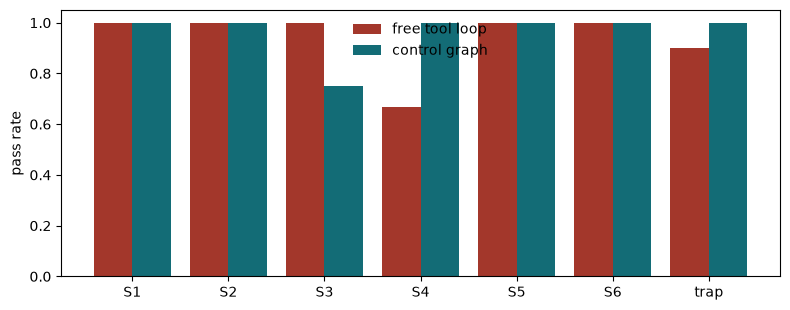

In [21]:
import matplotlib.pyplot as plt
S = {a: (load_log(f"forty_{a}.json") or {}).get("summary") for a in ("loop", "graph", "loop_lite", "graph_lite")}
S = {a: v for a, v in S.items() if v}
table = pd.DataFrame({a: {"passed (of 40)": s["passed"], "cases with a never-event": s["never_event_cases"],
                          "model calls": s["model_calls"], "tool calls": s["tool_calls"], "ERP services": s["services"],
                          "tokens": s["tokens_in"] + s["tokens_out"], "model seconds": s["seconds"], "₹": s["cost_inr"]}
                      for a, s in S.items()})
display(table)
fams = list(S["graph"]["by_family"]) if "graph" in S else []
fig, ax = plt.subplots(figsize=(8, 3.2))
x = range(len(fams))
ax.bar([i - 0.2 for i in x], [S["loop"]["by_family"][f]["passed"] / S["loop"]["by_family"][f]["cases"] for f in fams], 0.4, label="free tool loop", color="#A3372B")
ax.bar([i + 0.2 for i in x], [S["graph"]["by_family"][f]["passed"] / S["graph"]["by_family"][f]["cases"] for f in fams], 0.4, label="control graph", color="#136C76")
ax.set_xticks(list(x)); ax.set_xticklabels(fams); ax.set_ylabel("pass rate"); ax.legend(frameon=False); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

## 7 · Your module (starts assignment A4)

Your capstone module has its own process document. Turn it into a route:

1. **Spine.** Write the 5–8 steps every request walks, and which of your tools each step may call.
2. **Gates.** Find every *if* in the process document. Each becomes a named predicate over your state, with a detour; the default is to skip.
3. **Asks.** Which fields are required, which can memory or a lookup fill, and which must the user give?
4. **Decisions.** Which steps are judgements? Give each a typed decision (options + fields) and a threshold.
5. **Memory.** What is the draft, what does the user level learn, what does the company level cite?

Start from this skeleton; A4.md has the full brief and the checklist.

In [22]:
MY_SPINE = ["understand", "route", "collect", "check", "preview", "commit", "confirm"]
MY_GATES = {
    # "gate_name": (lambda state: <bool>, "detour node", "the rule it comes from"),
    "example_over_limit": (lambda s: (s.get("facts", {}).get("value") or 0) > 250000, "approval", "your approval matrix"),
}
for name, (pred, detour, rule) in MY_GATES.items():
    print(f"{name}: opens {detour} ({rule}); on an empty state -> {pred({})}")

example_over_limit: opens approval (your approval matrix); on an empty state -> False
